# Visualizing HRTF data 
Load and Understand HRTF Files:  
a.  Explore the structure of the files by checking the indices of Elevation and Azimuth. Load 
the HRIR data for a specific direction and a given ear (read the reference article) 

In [2]:
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt

files = sorted(glob.glob("Data/HRTFs/*.sofa"))
print(len(files))

f = h5py.File(files[0], "r")
print(len(f.keys()))
for k in f.keys():
    print(k, f[k].shape)


20
18
C (3,)
Data.Delay (1, 2)
Data.IR (1296, 2, 256)
Data.SamplingRate (1,)
E (1,)
EmitterPosition (1, 3, 1)
I (1,)
ListenerPosition (1, 3)
ListenerUp (1, 3)
ListenerView (1, 3)
M (1296,)
N (256,)
R (2,)
ReceiverPosition (2, 3, 1296)
S (0,)
SourcePosition (1296, 3)
SourceUp (1, 3)
SourceView (1, 3)


In [3]:
fs=f["Data.SamplingRate"][0]
fs

44100.0

In [4]:
pos = f["SourcePosition"][:]
print(pos.shape)
f["SourcePosition"].attrs["Units"]

(1296, 3)


b'degree, degree, metre'

In [5]:
pos[0:10]

array([[360.  , -41.04,   1.  ],
       [360.  , -36.  ,   1.  ],
       [360.  , -30.96,   1.  ],
       [360.  , -25.92,   1.  ],
       [360.  , -20.88,   1.  ],
       [360.  , -15.84,   1.  ],
       [360.  , -10.8 ,   1.  ],
       [360.  ,  -5.76,   1.  ],
       [360.  ,  -0.72,   1.  ],
       [360.  ,   4.32,   1.  ]])

In [6]:
hrirs = f["Data.IR"][:]
hrirs.shape

(1296, 2, 256)

In [7]:
az = pos[:, 0]
el = pos[:, 1]
dist = pos[:, 2]

elevations = np.unique(el)
print("Elevations:", elevations)
print(len(elevations), "\n")

azimuths = np.unique(az)
print("Azimuths:", azimuths)
print(len(azimuths), "\n")

distances = np.unique(dist)
print("Distances:", distances)
print(len(distances))

Elevations: [-41.04 -36.   -30.96 -25.92 -20.88 -15.84 -10.8   -5.76  -0.72   4.32
   9.36  14.4   19.44  24.48  29.52  34.56  39.6   44.64]
18 

Azimuths: [  5.  10.  15.  20.  25.  30.  35.  40.  45.  50.  55.  60.  65.  70.
  75.  80.  85.  90.  95. 100. 105. 110. 115. 120. 125. 130. 135. 140.
 145. 150. 155. 160. 165. 170. 175. 180. 185. 190. 195. 200. 205. 210.
 215. 220. 225. 230. 235. 240. 245. 250. 255. 260. 265. 270. 275. 280.
 285. 290. 295. 300. 305. 310. 315. 320. 325. 330. 335. 340. 345. 350.
 355. 360.]
72 

Distances: [1.]
1


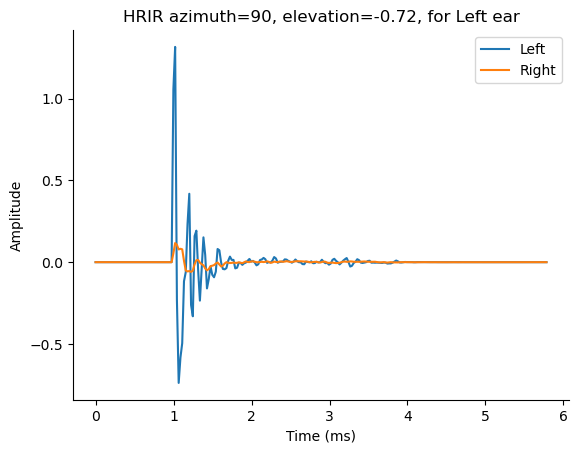

In [8]:
 # ear: 0 = left, 1 = right
target_az, target_el, ear = 90, 0, 0 
idx = np.argmin(np.abs(el - target_el) + np.abs((az - target_az + 180) % 360 - 180))

hrir = hrirs[idx, ear, :]

t = np.arange(len(hrir)) / fs * 1000
plt.plot(t, hrirs[idx, 0, :], label="Left")
plt.plot(t, hrirs[idx, 1, :], label="Right")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title(f"HRIR azimuth={az[idx]:g}, elevation={el[idx]:g}, for Left ear")
gca = plt.gca()
gca.spines["top"].set_visible(False)
gca.spines["right"].set_visible(False)
plt.legend()
plt.show()

b. Convert between HRTF and HRIR using FFT and IFFT 
-  Note: The toolkit should load the HRIR directly from the SOFA file. 

In [9]:
# HRIR -> HRTF
hrtf = np.fft.rfft(hrir)
freqs = np.fft.rfftfreq(len(hrir), 1 / fs)
mag_db = 20 * np.log10(np.abs(hrtf) + 1e-12)
phase = np.unwrap(np.angle(hrtf))
print("HRIR:", hrir.shape, "-> HRTF:", hrtf.shape)

# HRTF -> HRIR
hrir_back = np.fft.irfft(hrtf, n=len(hrir))
print("reconstruction error:", np.max(np.abs(hrir - hrir_back)))


HRIR: (256,) -> HRTF: (129,)
reconstruction error: 2.220446049250313e-16


All HRTFs: (1296, 2, 129) max error: 4.440892098500626e-16


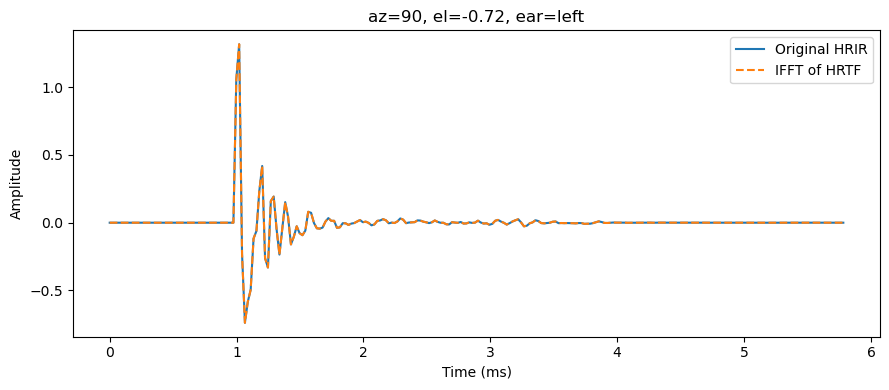

In [13]:
hrtfs = np.fft.rfft(hrirs, axis=-1)
hrirs_back = np.fft.irfft(hrtfs, n=len(hrir), axis=-1)
print("All HRTFs:", hrtfs.shape, "max error:", np.max(np.abs(hrirs - hrirs_back)))

t = np.arange(len(hrir)) / fs * 1000
plt.figure(figsize=(9, 4))
plt.plot(t, hrir, label="Original HRIR")
plt.plot(t, hrir_back, "--", label="IFFT of HRTF")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title(f"az={az[idx]:g}, el={el[idx]:g}, ear={'left' if ear == 0 else 'right'}")
plt.legend()
plt.tight_layout()
plt.show()

c. Apply an HRIR filter to a given audio clip.

In [14]:
import librosa
import soundfile as sf
from scipy.signal import fftconvolve

audio, _ = librosa.load("Data/Audio/music1.mp3", sr=int(fs))
filtered = np.stack([fftconvolve(audio, hrirs[idx, 0]), fftconvolve(audio, hrirs[idx, 1])], axis=1)
filtered /= np.max(np.abs(filtered)) # normalize
sf.write("Data/Audio/music1_hrirfiltered.wav", filtered, int(fs))

d. Visualize the HRTF data from different subjects:  
-  Azimuth HeatMap: Keep Elevation constant, plot a magnitude heatmap with the x-
axis as Azimuth (in degrees) and y-axis as frequency (in Hz) 
-  Elevation HeatMap: Keep Azimuth constant, plot a magnitude heatmap with the x-
axis as Elevation (in degrees) and y-axis as frequency (in Hz) 
-  Note: If your heatmap appears unclear, consider switching to a log scale for better 
visualization 

In [15]:
hrtfs.shape

(1296, 2, 129)

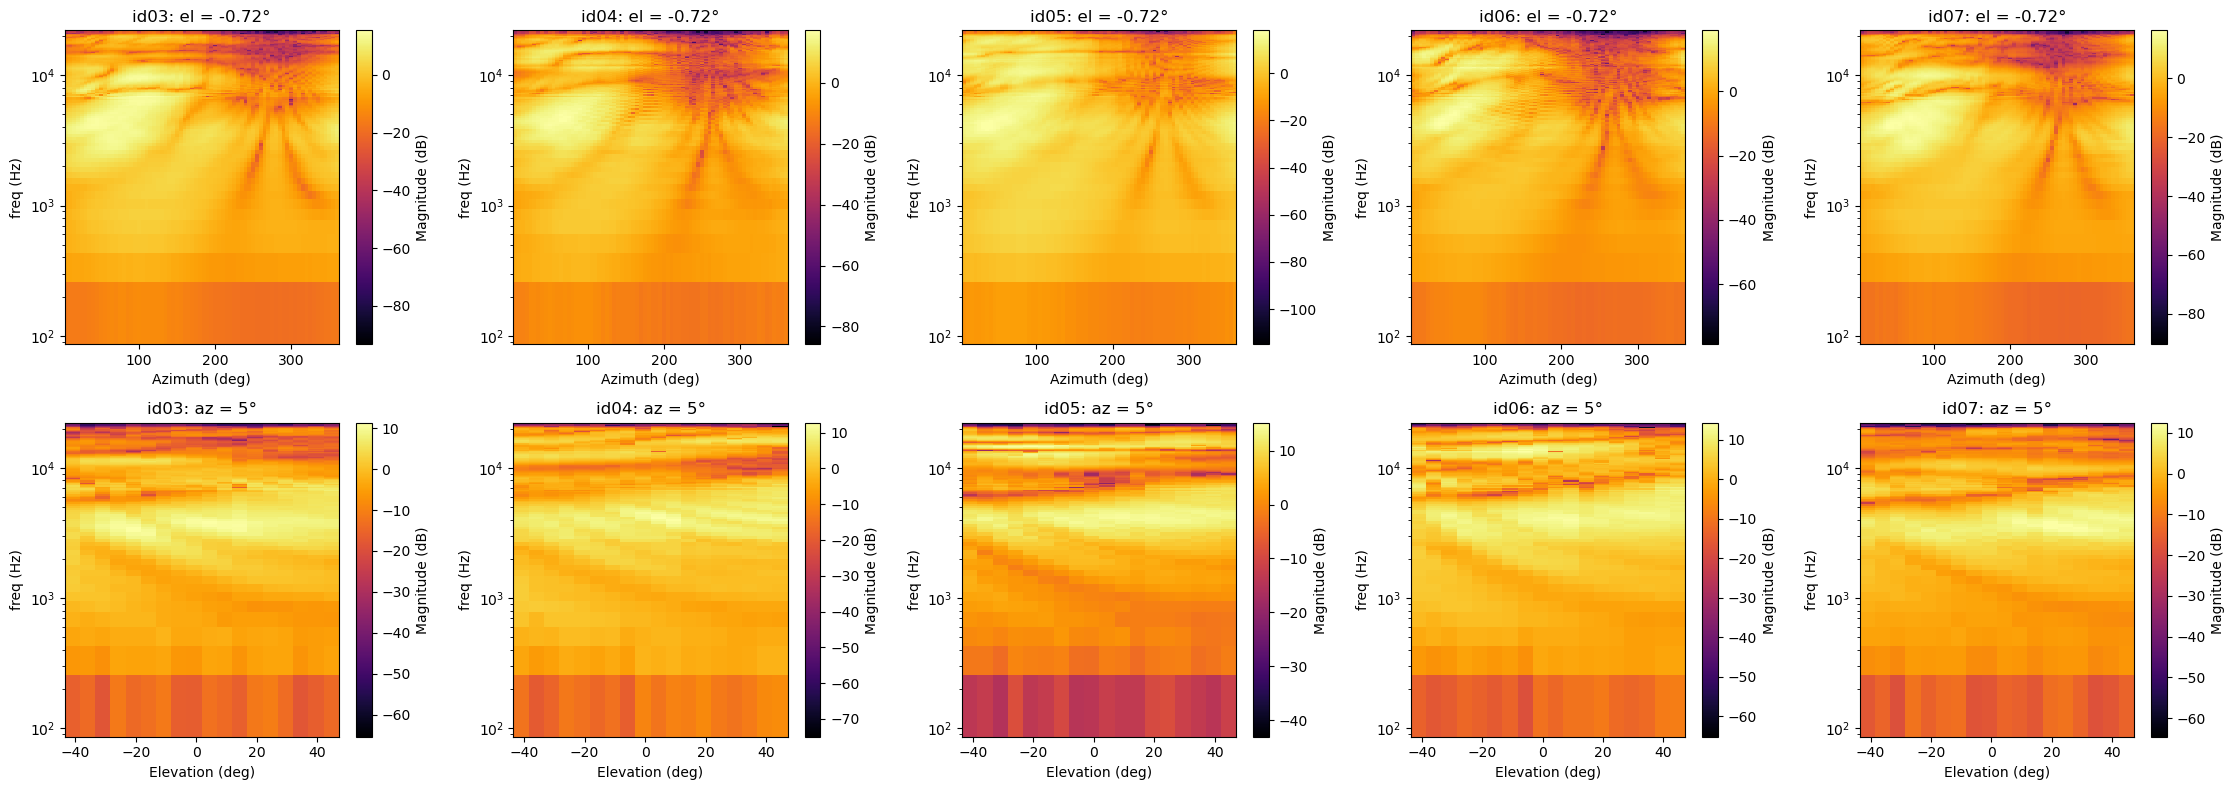

In [16]:
import os
const_el = 0
const_az = 0
ear = 0
subjects = files[2:7]
fig, ax = plt.subplots(2, len(subjects), figsize=(4.5 * len(subjects), 8), squeeze=False)

for i, path in enumerate(subjects):
    f = h5py.File(path, "r")
    hrirs = f["Data.IR"][:]
    fs = f["Data.SamplingRate"][0]
    pos = f["SourcePosition"][:]
    az = pos[:, 0]
    el = pos[:, 1]
    
    freqs = np.fft.rfftfreq(hrirs.shape[-1], 1 / fs)
    mag_db = 20 * np.log10(np.abs(np.fft.rfft(hrirs[:, ear, :], axis=-1)) + 1e-12)
    name = os.path.basename(path)[:4]

    actual_el = el[np.argmin(np.abs(el - const_el))]
    actual_az = az[np.argmin(np.abs(az - const_az))]

    sel = np.where(np.isclose(el, actual_el))[0]
    sel = sel[np.argsort(az[sel])]
    m = ax[0, i].pcolormesh(az[sel], freqs[1:], mag_db[sel, 1:].T, cmap="inferno")
    ax[0, i].set(yscale="log", xlabel="Azimuth (deg)", ylabel="freq (Hz)", title=f"{name}: el = {actual_el:g}°")
    fig.colorbar(m, ax=ax[0, i], label="Magnitude (dB)")

    sel = np.where(np.isclose(az, actual_az))[0]
    sel = sel[np.argsort(el[sel])]
    m = ax[1, i].pcolormesh(el[sel], freqs[1:], mag_db[sel, 1:].T, cmap="inferno")
    ax[1, i].set(yscale="log", xlabel="Elevation (deg)", ylabel="freq (Hz)", title=f"{name}: az = {actual_az:g}°")
    fig.colorbar(m, ax=ax[1, i], label="Magnitude (dB)")

plt.tight_layout()
plt.show()

f. Mean HRTF: 
Compute the mean magnitude across all subjects for the azimuth and elevation Heatmaps 
explored above and visualize them. 
Calculate the MSE (mean square error) between each subject’s HRTF and the mean 
HRTF  along  azimuth  and  elevation.  Identify  the  subject  closest  to  the  mean  and  the 
subject farthest from the mean HRTF along each direction.

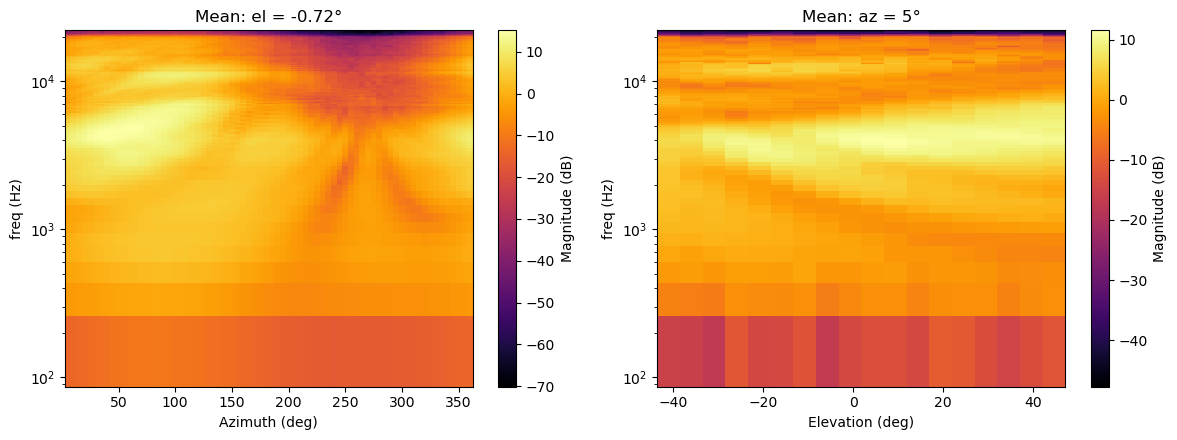

In [17]:
import os
subjects = files
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
az_maps, el_maps = [], []

for i, path in enumerate(subjects):
    f = h5py.File(path, "r")
    hrirs = f["Data.IR"][:]
    fs = f["Data.SamplingRate"][0]
    pos = f["SourcePosition"][:]
    az = pos[:, 0]
    el = pos[:, 1]
    
    freqs = np.fft.rfftfreq(hrirs.shape[-1], 1 / fs)
    mag_db = 20 * np.log10(np.abs(np.fft.rfft(hrirs[:, ear, :], axis=-1)) + 1e-12)

    actual_el = el[np.argmin(np.abs(el - const_el))]
    actual_az = az[np.argmin(np.abs(az - const_az))]

    sel = np.where(np.isclose(el, actual_el))[0]
    sel = sel[np.argsort(az[sel])]
    az_maps.append(mag_db[sel, 1:].T)
    az_x = az[sel]

    sel = np.where(np.isclose(az, actual_az))[0]
    sel = sel[np.argsort(el[sel])]
    el_maps.append(mag_db[sel, 1:].T)
    el_x = el[sel]
    
mean_az = np.mean(az_maps, axis=0)
mean_el = np.mean(el_maps, axis=0)

m = ax[0].pcolormesh(az_x, freqs[1:], mean_az, cmap="inferno")
ax[0].set(yscale="log", xlabel="Azimuth (deg)", ylabel="freq (Hz)", title=f"Mean: el = {actual_el:g}°")
fig.colorbar(m, ax=ax[0], label="Magnitude (dB)")

m = ax[1].pcolormesh(el_x, freqs[1:], mean_el, cmap="inferno")
ax[1].set(yscale="log", xlabel="Elevation (deg)", ylabel="freq (Hz)", title=f"Mean: az = {actual_az:g}°")
fig.colorbar(m, ax=ax[1], label="Magnitude (dB)")

plt.tight_layout()
plt.show()

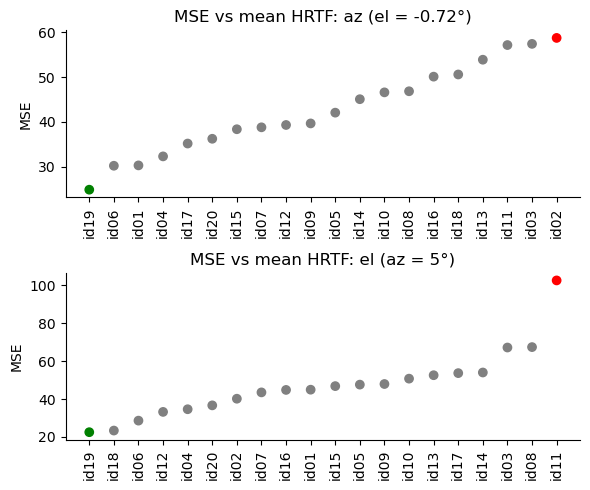

In [18]:
mse_az = np.array([np.mean((m - mean_az) ** 2) for m in az_maps])
mse_el = np.array([np.mean((m - mean_el) ** 2) for m in el_maps])
names = np.array([os.path.basename(p)[:4] for p in subjects])

fig, ax = plt.subplots(2, 1, figsize=(max(5, 0.3 * len(subjects)), 5))

for k, (mse, label) in enumerate([(mse_az, f"az (el = {actual_el:g}°)"), (mse_el, f"el (az = {actual_az:g}°)")]):
    order = np.argsort(mse)
    colors = ["gray"] * len(mse)
    colors[0], colors[-1] = "green", "red"
    ax[k].scatter(range(len(mse)), mse[order], c=colors)
    ax[k].set_xticks(range(len(mse)))
    ax[k].set_xticklabels(names[order], rotation=90)
    ax[k].set(ylabel="MSE", title=f"MSE vs mean HRTF: {label}")
    ax[k].spines["top"].set_visible(False)
    ax[k].spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

.


e.  Write a short analysis comparing the similarities and differences between these HRTF 
files across subjects. (Discuss at least 3 aspects, such as common patterns between 
magnitude  and  azimuth/elevation,  inter-subject  differences,  frequency-dependent 
differences and any other elements that stand out to you)

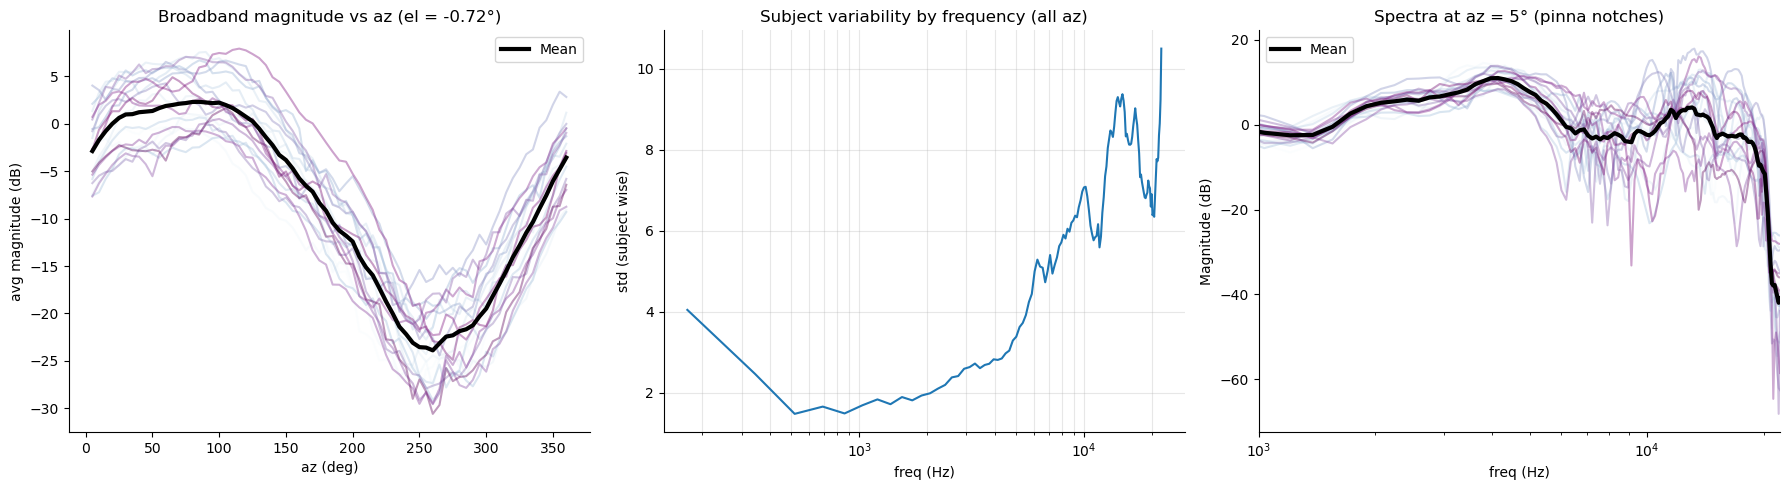

In [26]:
import numpy as np

A = np.array(az_maps)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for s in range(len(A)):
    ax[0].plot(az_x, A[s].mean(axis=0), alpha=0.4, color=plt.cm.BuPu(s / len(A)))
ax[0].plot(az_x, mean_az.mean(axis=0), "k", lw=3, label="Mean")
ax[0].set(xlabel="az (deg)", ylabel="avg magnitude (dB)", title=f"Broadband magnitude vs az (el = {actual_el:g}°)")
ax[0].legend()
ax[0].spines["top"].set_visible(False)
ax[0].spines["right"].set_visible(False)

std_f = A.std(axis=0).mean(axis=1)
ax[1].semilogx(freqs[1:], std_f)
ax[1].set(xlabel="freq (Hz)", ylabel="std (subject wise)", title="Subject variability by frequency (all az)")
ax[1].grid(True, which="both", alpha=0.3)
ax[1].spines["top"].set_visible(False)
ax[1].spines["right"].set_visible(False)

front = np.argmin(np.abs(az_x - 0))
for s in range(len(A)):
    ax[2].semilogx(freqs[1:], A[s][:, front], alpha=0.4, color=plt.cm.BuPu(s / len(A)))
ax[2].semilogx(freqs[1:], mean_az[:, front], "k", lw=3, label="Mean")
ax[2].set(xlabel="freq (Hz)", ylabel="Magnitude (dB)", xlim=(1000, freqs[-1]), title=f"Spectra at az = {az_x[front]:g}° (pinna notches)")
ax[2].legend()
ax[2].spines["top"].set_visible(False)
ax[2].spines["right"].set_visible(False)

plt.tight_layout()
plt.show()